### Lab - EDA Univariate Analysis: Diving into Amazon UK Product Insights

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [3]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [4]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


### Part 1. Understanding Product Categories

Business Question: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

In [5]:
# Frequency Tables:
frequency_table = df['category'].value_counts() #.sort_index()
frequency_table

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [6]:
# Which are the top 5 most listed product categories?
# 1. Sports & Outdoors 
# 2. Beauty                     
# 3. Handmade Clothing, Shoes & Accessories     
# 4. Bath & Body                                
# 5. Birthday Gifts      

In [7]:
# Visualizations

<Axes: xlabel='category'>

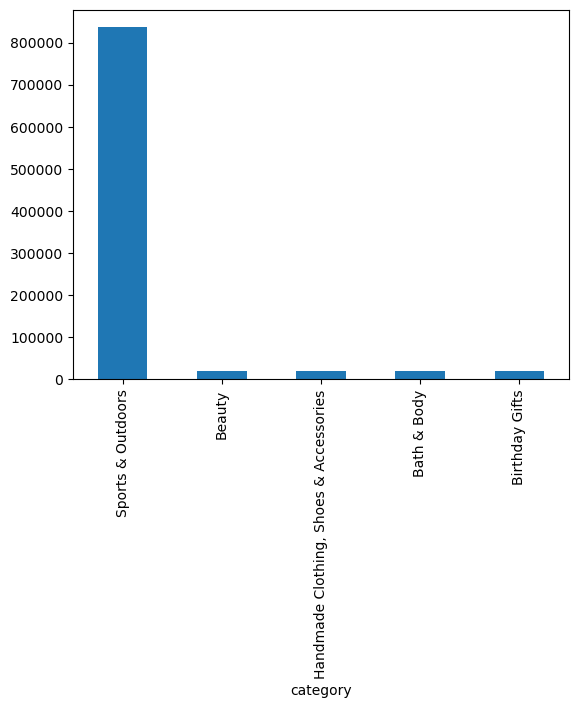

In [8]:
top_categories = frequency_table.head(5)
top_categories.plot(kind = 'bar')

<Axes: xlabel='category'>

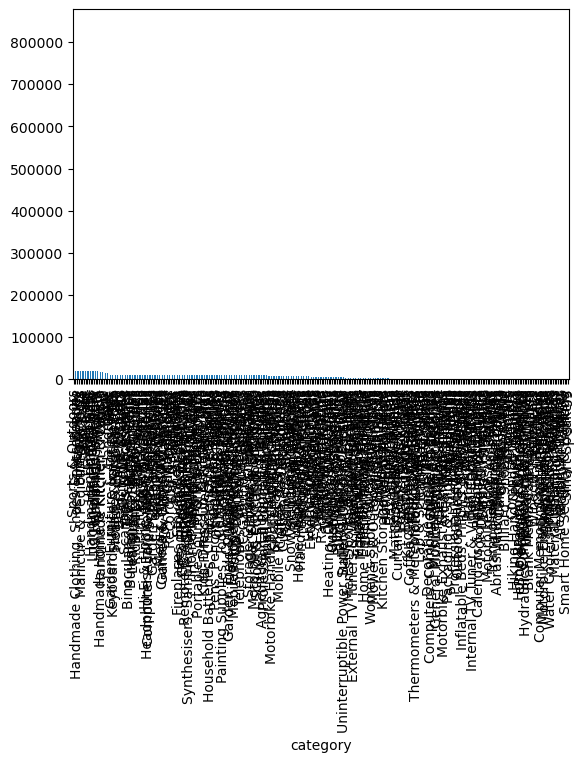

In [9]:
frequency_table.plot(kind = 'bar')

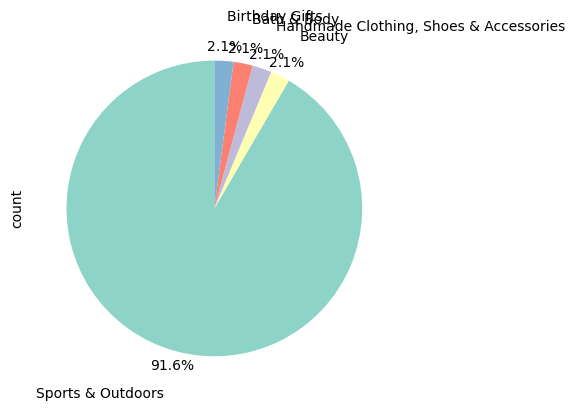

In [10]:
top_categories.plot.pie(labels=top_categories.index,
                                       autopct='%.1f%%',
                                       startangle=90, 
                                       colors=sns.color_palette("Set3"),
                                       pctdistance=1.1, 
                                       labeldistance=1.3)

plt.show()

In [11]:
# Does any category dominate the listings
# Sports & Outdoors

### Part 2: Delving into Product Pricing

Business Question: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

In [12]:
# Measures of Centrality
mean = df['price'].mean()
median = df['price'].median()
mode = df['price'].mode()[0]

print('Mean: ', mean)
print('Median: ',median)
print('Mode: ', mode)

Mean:  89.24380943923661
Median:  19.09
Mode:  9.99


In [13]:
# What's the average price point of products listed? How does this compare with the most common price point (mode)?
# The average product price is 89.24, while the most common price is only 9.99. 
# The large difference suggests that some high-priced products are pulling the average upwards.

In [14]:
# Measures of Dispersion
variance = df['price'].var()
st_dev = df['price'].std()
min_price = df['price'].min()
max_price = df['price'].max()
range_price = max_price - min_price
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

print('Variance: ', variance)
print('St_dev: ', st_dev)
print('Range: ', range_price)
print('IQR: ', IQR)

Variance:  119445.48532256528
St_dev:  345.60886175352226
Range:  100000.0
IQR:  36.0


In [15]:
# How varied are the product prices? Are there any indicators of a significant spread in prices?
# Product prices show a significant spread, with a very large range (£100,000) and standard deviation (£345.61). 
# However, the IQR is only £36, suggesting that most products have relatively similar prices, while a few very expensive products create the large spread.

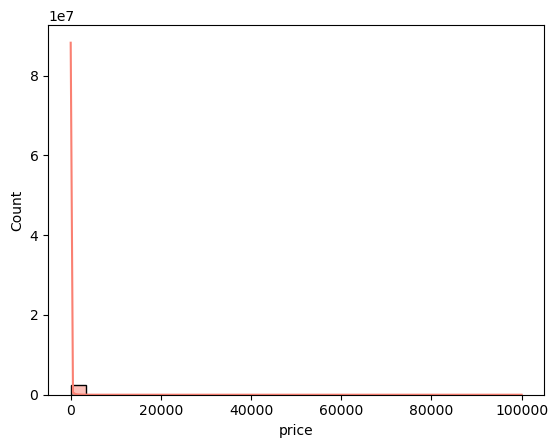

In [16]:
# Visualizations    
fig, axes = plt.subplots()
sns.histplot(df['price'], kde=True, bins=30, color="salmon", ax=axes);
plt.show()

In [17]:
# The histogram is difficult to read because a few extremely high-priced products stretch the x-axis. Most products are concentrated at much lower prices.
# We can limit the x-axis to £500 and increased the number of bins to better visualize the distribution of the most common prices.

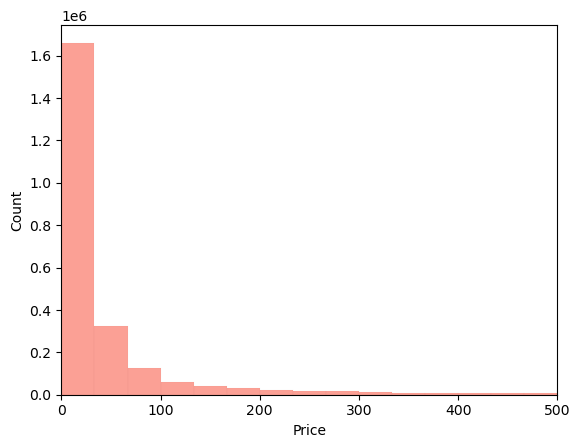

In [20]:
sns.histplot(df['price'], bins=3000, color="salmon")

plt.xlim(0, 500)
plt.xlabel('Price')
plt.ylabel('Count')
plt.show()


In [ ]:
# The second histogram shows that most products are concentrated at lower price points, mainly below £100, with fewer products at higher prices.

In [ ]:
# Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.

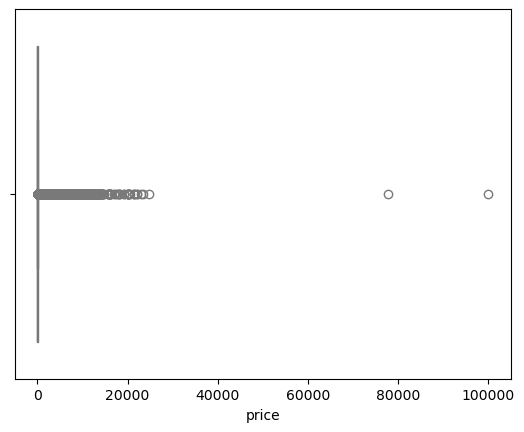

In [40]:
sns.boxplot(x = df['price'], color="lightblue");

In [21]:
# The box plot shows several high-priced outliers, indicating that some products are priced significantly higher than the majority.

### Part 3: Unpacking Product Ratings

Business Question: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

In [22]:
# Measures of Centrality
mean = df['stars'].mean()
median = df['stars'].median()
mode = df['stars'].mode()[0]

print('Mean: ', mean)
print('Median: ',median)
print('Mode: ', mode)

Mean:  2.152836472966066
Median:  0.0
Mode:  0.0


In [ ]:
# How do customers generally rate products? Is there a common trend?
# The mean rating is 2.15, while both the median and mode are 0.This suggests that ratings are generally low, with 0 being the most common value.

In [26]:
# Measures of Dispersion
variance = df['stars'].var()
st_dev = df['stars'].std()
min_price = df['stars'].min()
max_price = df['stars'].max()
range_price = max_price - min_price
Q1 = df['stars'].quantile(0.25)
Q3 = df['stars'].quantile(0.75)
IQR = Q3 - Q1

print('Variance: ', variance)
print('St_dev: ', st_dev)
print('Range: ', range_price)
print('IQR: ', IQR)

Variance:  4.81743402976196
St_dev:  2.1948653785054697
Range:  5.0
IQR:  4.4


In [ ]:
# Are the ratings consistent, or is there a wide variation in customer feedback?
# The ratings show considerable variation, with a standard deviation of 2.19 and an IQR of 4.4.

In [27]:
# Shape of the Distribution
skewness_price = df['stars'].skew()
kurtosis_price = df['stars'].kurtosis()

skewness_price, kurtosis_price

(np.float64(0.08120735761080881), np.float64(-1.9260061280432994))

In [28]:
# Are the ratings normally distributed, or do they lean towards higher or lower values?
# Based on the skewness value, the distribution appears approximately symmetric,with very little skewness. 

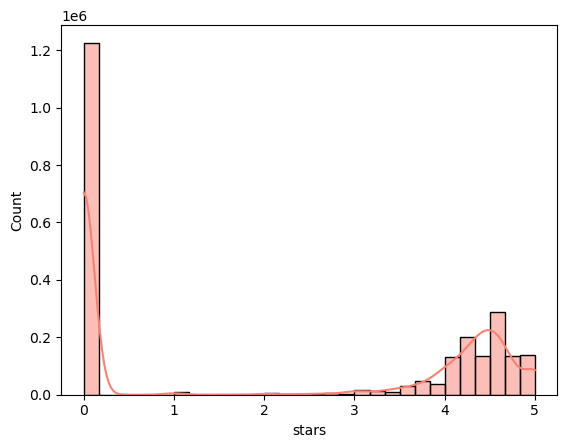

In [30]:
# Visualizations
fig, axes = plt.subplots()
sns.histplot(df['stars'], kde=True, bins=30, color="salmon", ax=axes);
plt.show()

In [29]:
# Is there a specific rating that is more common?
# The histogram shows that 0 is clearly the most common value.